# Problema 1 — Inciso (c): tabla por grupo, identidad y bootstrap

Esta libreta parte de las probabilidades calibradas que guardó
`04_calibracion` y construye la tabla de desempeño por grupo definido por
`SEX`:

- **Hombres:** `SEX = 1`.
- **Mujeres:** `SEX = 2`.

Reglas que respeta:

- Usa `resultados/04_probabilidades_calibradas_test.csv`. Si el método de
  calibración hubiera sido `sin_calibrar`, usaría `prob_sin_calibrar`; como
  `04_calibracion` eligió un calibrador global isotónico, usa
  `prob_calibrada`.
- Umbral del banco confirmado en `common.py`: `G = 1`, `L = 5`,
  `UMBRAL = G / (G + L) = 1/6`. Se **rechaza** al cliente si su puntaje es
  `>= 1/6`.
- `SEX` **no** fue variable de entrada del modelo ni del calibrador. Aquí
  solo se usa como variable de auditoría para separar los grupos.
- Las divisiones entre cero se manejan devolviendo `NaN` y registrando un
  aviso explícito, en vez de fallar o inventar un valor.
- El bootstrap remuestrea **todo** el conjunto de prueba con reemplazo, tal
  como pide el inciso, y usa la semilla `SEED` de `common.py`.

In [1]:
"""Configuración, rutas e importaciones de la libreta."""

from __future__ import annotations

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display


def _buscar_raiz(inicio: Path) -> Path:
    """Sube desde el directorio actual hasta encontrar la raíz del repo.

    La raíz se reconoce porque contiene `common.py` y la carpeta `problema-1/`.
    Así la libreta funciona igual si se abre desde la raíz o desde
    `problema-1/`, y también cuando la ejecuta `nbconvert`.
    """
    for base in [inicio, *inicio.parents]:
        if (base / "common.py").exists() and (base / "problema-1").is_dir():
            return base
    return inicio


_AQUI = Path.cwd()
_RAIZ = _buscar_raiz(_AQUI)
_DIR_PROBLEMA = _RAIZ / "problema-1" if (_RAIZ / "problema-1").is_dir() else _RAIZ

# Permite importar common.py (raíz) y los módulos de problema-1/.
for _ruta in (_RAIZ, _DIR_PROBLEMA):
    if str(_ruta) not in sys.path:
        sys.path.insert(0, str(_ruta))

from common import G, L, SEED, UMBRAL  # noqa: E402

RESULTADOS = _RAIZ / "resultados"
RESULTADOS.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_rows", None)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", None)
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

# Número de réplicas bootstrap que pide el inciso.
N_BOOTSTRAP = 2000

print(f"SEED = {SEED}")
print(f"G = {G}, L = {L}, UMBRAL = G/(G+L) = {UMBRAL:.12f}")
print(f"Directorio de resultados = {RESULTADOS}")
print(f"Réplicas bootstrap = {N_BOOTSTRAP}")

SEED = 223210350
G = 1, L = 5, UMBRAL = G/(G+L) = 0.166666666667
Directorio de resultados = /home/tito/repos/RDP/Examen_1_RDP/resultados
Réplicas bootstrap = 2000


## 1. Carga y elección de las probabilidades

Primero se lee `resultados/04_metodo_calibracion.csv` para saber qué método
de calibración se eligió en el inciso (b). La regla es:

- Si el método es `sigmoid` o `isotonic`, se usa la columna
  `prob_calibrada`.
- Si el método es `sin_calibrar`, se usa `prob_sin_calibrar`.

También se valida que el archivo de probabilidades siga alineado con el
split 70/30 guardado y con el dataset original. Esa validación evita
construir una tabla por grupo con filas desordenadas o de otro split.

In [2]:
ruta_probabilidades = RESULTADOS / "04_probabilidades_calibradas_test.csv"
ruta_metodo = RESULTADOS / "04_metodo_calibracion.csv"
ruta_split = RESULTADOS / "split_indices.csv"

for ruta in (ruta_probabilidades, ruta_metodo, ruta_split):
    if not ruta.exists():
        raise FileNotFoundError(
            f"No existe {ruta}. Ejecuta primero 04_calibracion.ipynb."
        )

tabla_probabilidades = pd.read_csv(ruta_probabilidades)
tabla_metodo = pd.read_csv(ruta_metodo)
metodo_calibracion = str(tabla_metodo.loc[0, "metodo_calibracion"])

columnas_necesarias = {
    "indice",
    "objetivo",
    "SEX",
    "prob_sin_calibrar",
    "prob_calibrada",
}
if not columnas_necesarias.issubset(tabla_probabilidades.columns):
    raise ValueError(
        "04_probabilidades_calibradas_test.csv no tiene las columnas "
        f"esperadas: {sorted(columnas_necesarias - set(tabla_probabilidades.columns))}."
    )

if metodo_calibracion == "sin_calibrar":
    columna_probabilidad = "prob_sin_calibrar"
    descripcion_probabilidad = (
        "probabilidades originales (04 no calibró el modelo)"
    )
elif metodo_calibracion in {"sigmoid", "isotonic"}:
    columna_probabilidad = "prob_calibrada"
    descripcion_probabilidad = (
        f"probabilidades calibradas con el método global '{metodo_calibracion}'"
    )
else:
    raise ValueError(
        f"Método de calibración desconocido en {ruta_metodo}: "
        f"'{metodo_calibracion}'."
    )

# Cargamos el dataset solo para validar índices, objetivo y SEX.
from data import TARGET, cargar_dataframe  # noqa: E402

df = cargar_dataframe()
indices = tabla_probabilidades["indice"].to_numpy()
if len(np.unique(indices)) != len(indices):
    raise ValueError("El archivo de probabilidades tiene índices duplicados.")
if indices.min() < 0 or indices.max() >= len(df):
    raise ValueError("El archivo de probabilidades tiene índices fuera de rango.")

if not np.array_equal(
    tabla_probabilidades["objetivo"].to_numpy(),
    df.iloc[indices][TARGET].to_numpy(),
):
    raise ValueError(
        "La columna 'objetivo' no coincide con el dataset para esos índices."
    )
if not np.array_equal(
    tabla_probabilidades["SEX"].to_numpy(),
    df.iloc[indices]["SEX"].to_numpy(),
):
    raise ValueError(
        "La columna 'SEX' no coincide con el dataset para esos índices."
    )

# El split de prueba debe ser exactamente el 30% guardado.
tabla_split = pd.read_csv(ruta_split)
indices_test_guardados = tabla_split.loc[
    tabla_split["conjunto"] == "test", "indice"
].to_numpy()
if not np.array_equal(np.sort(indices), np.sort(indices_test_guardados)):
    raise ValueError(
        "Los índices de 04_probabilidades_calibradas_test.csv no coinciden "
        "con el conjunto de prueba de split_indices.csv."
    )

y_test = tabla_probabilidades["objetivo"].to_numpy(dtype=int)
sexo_test = tabla_probabilidades["SEX"].to_numpy(dtype=int)
probabilidad_test = tabla_probabilidades[columna_probabilidad].to_numpy(
    dtype=float
)

if not np.all(np.isfinite(probabilidad_test)):
    raise ValueError("Hay probabilidades no finitas en el archivo de entrada.")
if not np.all((probabilidad_test >= 0) & (probabilidad_test <= 1)):
    raise ValueError("Hay probabilidades fuera del intervalo [0, 1].")
if not set(np.unique(sexo_test)).issubset({1, 2}):
    raise ValueError(
        f"SEX contiene valores inesperados: {sorted(np.unique(sexo_test))}."
    )

# Decisión operativa del banco: rechazar si el puntaje alcanza el umbral.
rechazo_test = probabilidad_test >= UMBRAL

print(f"Método de calibración registrado: {metodo_calibracion}")
print(f"Columna usada: {columna_probabilidad} ({descripcion_probabilidad})")
print(f"Filas de prueba: {len(y_test)}")
print(f"Rechazo total con umbral {UMBRAL:.6f}: {rechazo_test.mean():.6f}")
print(
    "Composición por SEX: "
    f"hombres = {int((sexo_test == 1).sum())}, "
    f"mujeres = {int((sexo_test == 2).sum())}."
)

Método de calibración registrado: isotonic
Columna usada: prob_calibrada (probabilidades calibradas con el método global 'isotonic')
Filas de prueba: 9000
Rechazo total con umbral 0.166667: 0.428889
Composición por SEX: hombres = 3584, mujeres = 5416.


La libreta usa **`prob_calibrada`**, es decir, las probabilidades del
calibrador global isotónico elegido en el inciso (b). La validación confirma
que las 9,000 filas son exactamente el 30% de prueba y que `objetivo` y
`SEX` coinciden con el dataset. El umbral `1/6 ≈ 0.166667` rechaza al
`42.89%` de toda la prueba. `SEX` sigue siendo solo una etiqueta de
auditoría: no participó en el modelo ni en el calibrador.

## 2. Métricas por grupo y manejo de divisiones entre cero

Para cada grupo se calculan las cuatro celdas de la matriz de confusión:

- `TP`: incumplió y fue rechazado.
- `FN`: incumplió y no fue rechazado.
- `FP`: no incumplió y fue rechazado.
- `TN`: no incumplió y no fue rechazado.

A partir de ellas se definen:

- `p_g = (TP + FN) / n`: tasa real de incumplimiento del grupo.
- `tasa_rechazo = (TP + FP) / n`: fracción del grupo que el banco rechaza.
- `PPV = TP / (TP + FP)`: de los rechazados, fracción que sí incumplió.
- `FPR = FP / (FP + TN)`: de los que no incumplieron, fracción rechazada.
- `FNR = FN / (TP + FN)`: de los que sí incumplieron, fracción no
  rechazada.

Si un denominador vale cero, la métrica correspondiente se devuelve como
`NaN` y se agrega un aviso a la lista `avisos`. No se sustituye por cero
porque eso ocultaría que la métrica no está definida.

In [3]:
def metricas_grupo(
    y: np.ndarray,
    rechazo: np.ndarray,
    nombre: str,
    avisos: list[str] | None = None,
) -> dict[str, float | int | str]:
    """Calcula n, p_g, tasa de rechazo, PPV, FPR y FNR de un grupo.

    ``y`` son las etiquetas reales (1 = incumplió) y ``rechazo`` indica si el
    banco rechazó al cliente. Cuando un denominador es cero, la métrica se
    devuelve como ``NaN`` y se registra un aviso legible.
    """
    y = np.asarray(y, dtype=int)
    rechazo = np.asarray(rechazo, dtype=bool)
    if avisos is None:
        avisos = []

    n = int(len(y))
    tp = int(np.sum((y == 1) & rechazo))
    fn = int(np.sum((y == 1) & ~rechazo))
    fp = int(np.sum((y == 0) & rechazo))
    tn = int(np.sum((y == 0) & ~rechazo))

    positivos = tp + fn
    negativos = fp + tn
    rechazados = tp + fp

    p_g = positivos / n if n > 0 else np.nan
    tasa_rechazo = rechazados / n if n > 0 else np.nan
    ppv = tp / rechazados if rechazados > 0 else np.nan
    fpr = fp / negativos if negativos > 0 else np.nan
    fnr = fn / positivos if positivos > 0 else np.nan

    # Avisos explícitos: el inciso pide enterarse si ocurre una división
    # entre cero, no solo obtener NaN en silencio.
    if n == 0:
        avisos.append(f"{nombre}: n = 0; p_g y tasa de rechazo no definidas.")
    if rechazados == 0:
        avisos.append(f"{nombre}: TP + FP = 0; PPV no definida.")
    if negativos == 0:
        avisos.append(f"{nombre}: FP + TN = 0; FPR no definida.")
    if positivos == 0:
        avisos.append(f"{nombre}: TP + FN = 0; FNR no definida.")

    return {
        "grupo": nombre,
        "n": n,
        "p_g": float(p_g),
        "tasa_rechazo": float(tasa_rechazo),
        "PPV": float(ppv),
        "FPR": float(fpr),
        "FNR": float(fnr),
        "TP": tp,
        "FN": fn,
        "FP": fp,
        "TN": tn,
    }


def construir_tabla_grupos(
    y: np.ndarray, rechazo: np.ndarray, sexo: np.ndarray
) -> tuple[pd.DataFrame, list[str]]:
    """Construye la tabla de hombres y mujeres y devuelve los avisos."""
    avisos: list[str] = []
    filas = []
    for valor, nombre in ((1, "Hombres (SEX=1)"), (2, "Mujeres (SEX=2)")):
        mascara = sexo == valor
        filas.append(
            metricas_grupo(y[mascara], rechazo[mascara], nombre, avisos)
        )
    return pd.DataFrame(filas), avisos


tabla_grupos, avisos_grupos = construir_tabla_grupos(
    y_test, rechazo_test, sexo_test
)

columnas_tabla = [
    "grupo",
    "n",
    "p_g",
    "tasa_rechazo",
    "PPV",
    "FPR",
    "FNR",
    "TP",
    "FN",
    "FP",
    "TN",
]
display(tabla_grupos[columnas_tabla].round(6))

ruta_tabla_grupos = RESULTADOS / "05_tabla_grupos.csv"
tabla_grupos[columnas_tabla].to_csv(
    ruta_tabla_grupos, index=False, float_format="%.8f"
)

print(f"Tabla guardada en: {ruta_tabla_grupos}")
if avisos_grupos:
    print("AVISOS de división entre cero en la tabla por grupo:")
    for aviso in avisos_grupos:
        print(f"  - {aviso}")
else:
    print(
        "No ocurrió ninguna división entre cero en la tabla por grupo: "
        "todos los denominadores son positivos."
    )

,grupo,n,p_g,tasa_rechazo,PPV,FPR,FNR,TP,FN,FP,TN
0,Hombres (SEX=1),3584,0.232980,0.456473,0.382641,0.367406,0.250299,626,209,1010,1739
1,Mujeres (SEX=2),5416,0.213442,0.410635,0.377248,0.325117,0.274221,839,317,1385,2875


Tabla guardada en: /home/tito/repos/RDP/Examen_1_RDP/resultados/05_tabla_grupos.csv
No ocurrió ninguna división entre cero en la tabla por grupo: todos los denominadores son positivos.


La tabla muestra que los hombres tienen una tasa real de incumplimiento
mayor (`0.232980` frente a `0.213442`) y también una tasa de rechazo mayor
(`0.456473` frente a `0.410635`). La `PPV` es muy parecida (`0.382641` en
hombres y `0.377248` en mujeres): entre los rechazados, alrededor del 38% sí
habría incumplido en ambos grupos. La diferencia está en los errores: el
`FPR` de hombres es `0.367406` y el de mujeres `0.325117`, es decir, se
rechaza a una fracción mayor de hombres que **no** iban a incumplir. En
cambio, el `FNR` de hombres es menor (`0.250299` frente a `0.274221`): se
les escapa una fracción algo menor de incumplidores. Ninguna división entre
cero ocurrió porque los cuatro denominadores son positivos en ambos grupos.

## 3. Verificación numérica de la identidad

La identidad que pide el inciso es:

$$
FPR = \frac{p}{1-p} \cdot \frac{1-PPV}{PPV} \cdot (1-FNR)
$$

donde `p` es la tasa real de incumplimiento del grupo. Esta identidad es
algebraica: se obtiene de sustituir las definiciones de `PPV`, `FPR` y `FNR`
sobre la misma matriz de confusión. Por eso el error absoluto debe ser cero
salvo por el redondeo de punto flotante. La verificación sirve para detectar
errores de implementación (por ejemplo, haber mezclado denominadores), no
para validar el modelo. Si el error fuera grande, indicaría que alguna
métrica se calculó con otra población o con otro umbral.

In [4]:
def verificar_identidad(fila: pd.Series, avisos: list[str]) -> dict[str, float]:
    """Evalúa la identidad y devuelve el valor calculado y el error absoluto.

    La identidad solo está definida si ``p`` no es 0 ni 1, ``PPV`` es mayor que
    cero y ``FNR`` es finita. En caso contrario se devuelve ``NaN`` y se
    registra el motivo.
    """
    p = float(fila["p_g"])
    ppv = float(fila["PPV"])
    fpr = float(fila["FPR"])
    fnr = float(fila["FNR"])
    grupo = str(fila["grupo"])

    if not np.isfinite(p) or p <= 0.0 or p >= 1.0:
        avisos.append(
            f"{grupo}: p_g = {p}; la identidad requiere 0 < p_g < 1."
        )
        return {"FPR_identidad": np.nan, "error_absoluto": np.nan}
    if not np.isfinite(ppv) or ppv <= 0.0:
        avisos.append(
            f"{grupo}: PPV = {ppv}; la identidad requiere PPV > 0."
        )
        return {"FPR_identidad": np.nan, "error_absoluto": np.nan}
    if not np.isfinite(fnr):
        avisos.append(f"{grupo}: FNR no definida; no se puede verificar.")
        return {"FPR_identidad": np.nan, "error_absoluto": np.nan}

    fpr_identidad = (p / (1.0 - p)) * ((1.0 - ppv) / ppv) * (1.0 - fnr)
    error = abs(fpr - fpr_identidad) if np.isfinite(fpr) else np.nan
    return {"FPR_identidad": float(fpr_identidad), "error_absoluto": float(error)}


avisos_identidad: list[str] = []
tabla_identidad = tabla_grupos[["grupo", "p_g", "PPV", "FPR", "FNR"]].copy()
verificaciones = [
    verificar_identidad(fila, avisos_identidad)
    for _, fila in tabla_grupos.iterrows()
]
tabla_identidad["FPR_identidad"] = [v["FPR_identidad"] for v in verificaciones]
tabla_identidad["error_absoluto"] = [v["error_absoluto"] for v in verificaciones]

# Para que el error de punto flotante sea visible, se muestra en notación
# científica en vez de redondearlo a cero.
tabla_identidad_mostrar = tabla_identidad.copy()
for columna in ("p_g", "PPV", "FPR", "FNR", "FPR_identidad"):
    tabla_identidad_mostrar[columna] = tabla_identidad_mostrar[columna].map(
        lambda valor: f"{valor:.12f}"
    )
tabla_identidad_mostrar["error_absoluto"] = tabla_identidad_mostrar[
    "error_absoluto"
].map(lambda valor: f"{valor:.3e}")
display(tabla_identidad_mostrar)

ruta_identidad = RESULTADOS / "05_identidad_fpr.csv"
tabla_identidad.to_csv(
    ruta_identidad, index=False, float_format="%.12e"
)
print(f"Verificación guardada en: {ruta_identidad}")
if avisos_identidad:
    print("AVISOS al verificar la identidad:")
    for aviso in avisos_identidad:
        print(f"  - {aviso}")
else:
    print("La identidad se pudo evaluar en ambos grupos.")

,grupo,p_g,PPV,FPR,FNR,FPR_identidad,error_absoluto
0,Hombres (SEX=1),0.232979910714,0.382640586797,0.367406329574,0.250299401198,0.367406329574,5.551e-17
1,Mujeres (SEX=2),0.213441654357,0.377248201439,0.325117370892,0.274221453287,0.325117370892,0.000e+00


Verificación guardada en: /home/tito/repos/RDP/Examen_1_RDP/resultados/05_identidad_fpr.csv
La identidad se pudo evaluar en ambos grupos.


La identidad se cumple con error absoluto prácticamente nulo: del orden de
`5.55e-17` en hombres y `0.0` en mujeres. Esos valores son ruido de punto
flotante, no una coincidencia empírica. La comprobación confirma que `p_g`,
`PPV`, `FPR` y `FNR` salen de la misma matriz de confusión y con el mismo
umbral `1/6`. Si alguna se hubiera calculado con otro denominador o con otro
umbral, el error habría sido visible.

## 4. Bootstrap del conjunto de prueba

Para saber si las diferencias entre grupos pueden ser ruido, se hace un
bootstrap no paramétrico:

- Se remuestrean **las 9,000 filas de prueba completas** con reemplazo.
- En cada réplica se separan hombres y mujeres y se recalculan `FPR` y
  `FNR`.
- Se guardan las diferencias `FPR_H − FPR_M` y `FNR_H − FNR_M`.
- El intervalo del 95% se obtiene por percentiles (`2.5` y `97.5`).

Se remuestrea todo el conjunto, no cada grupo por separado, porque así se
refleja también la variabilidad del tamaño relativo de cada grupo. La semilla
`SEED` se usa en un generador propio (`np.random.default_rng`), de modo que
el resultado no depende de otras llamadas aleatorias del repositorio.

In [5]:
def diferencias_por_grupo(
    y: np.ndarray,
    rechazo: np.ndarray,
    sexo: np.ndarray,
    avisos: list[str] | None = None,
) -> tuple[float, float]:
    """Devuelve ``FPR_H - FPR_M`` y ``FNR_H - FNR_M`` de una muestra.

    Si alguna de las cuatro métricas no está definida, devuelve ``NaN`` en la
    diferencia correspondiente y registra el aviso.
    """
    if avisos is None:
        avisos = []
    hombres = metricas_grupo(
        y[sexo == 1], rechazo[sexo == 1], "Hombres", avisos
    )
    mujeres = metricas_grupo(
        y[sexo == 2], rechazo[sexo == 2], "Mujeres", avisos
    )

    if np.isfinite(hombres["FPR"]) and np.isfinite(mujeres["FPR"]):
        diferencia_fpr = float(hombres["FPR"] - mujeres["FPR"])
    else:
        diferencia_fpr = np.nan

    if np.isfinite(hombres["FNR"]) and np.isfinite(mujeres["FNR"]):
        diferencia_fnr = float(hombres["FNR"] - mujeres["FNR"])
    else:
        diferencia_fnr = np.nan

    return diferencia_fpr, diferencia_fnr


# Diferencia observada en la muestra original, sin remuestreo.
dif_fpr_observada, dif_fnr_observada = diferencias_por_grupo(
    y_test, rechazo_test, sexo_test
)

rng = np.random.default_rng(SEED)
n_test = len(y_test)
diferencias_fpr = np.empty(N_BOOTSTRAP, dtype=float)
diferencias_fnr = np.empty(N_BOOTSTRAP, dtype=float)
replicas_invalidas = 0

for b in range(N_BOOTSTRAP):
    # Remuestreo con reemplazo de todas las filas de prueba.
    indices_bootstrap = rng.integers(0, n_test, size=n_test)
    dif_fpr, dif_fnr = diferencias_por_grupo(
        y_test[indices_bootstrap],
        rechazo_test[indices_bootstrap],
        sexo_test[indices_bootstrap],
    )
    diferencias_fpr[b] = dif_fpr
    diferencias_fnr[b] = dif_fnr
    if not (np.isfinite(dif_fpr) and np.isfinite(dif_fnr)):
        replicas_invalidas += 1

if replicas_invalidas > 0:
    print(
        "AVISO: "
        f"{replicas_invalidas} de {N_BOOTSTRAP} réplicas bootstrap tuvieron "
        "alguna métrica no definida. Se excluyen del intervalo."
    )
else:
    print(
        "Ninguna réplica bootstrap tuvo divisiones entre cero: "
        f"las {N_BOOTSTRAP} réplicas son válidas."
    )


def resumen_bootstrap(
    nombre: str, observada: float, replicas: np.ndarray
) -> dict[str, float | int | str]:
    """Resume una diferencia bootstrap con su IC del 95% por percentiles."""
    validas = replicas[np.isfinite(replicas)]
    inferior, superior = np.percentile(validas, [2.5, 97.5])
    return {
        "diferencia": nombre,
        "observada": float(observada),
        "media_bootstrap": float(validas.mean()),
        "sd_bootstrap": float(validas.std(ddof=1)),
        "ic95_inferior": float(inferior),
        "ic95_superior": float(superior),
        "contiene_cero": "sí" if inferior <= 0.0 <= superior else "no",
        "replicas_validas": int(len(validas)),
        "replicas_invalidas": int(N_BOOTSTRAP - len(validas)),
    }


filas_bootstrap = [
    resumen_bootstrap("FPR_H - FPR_M", dif_fpr_observada, diferencias_fpr),
    resumen_bootstrap("FNR_H - FNR_M", dif_fnr_observada, diferencias_fnr),
]
tabla_bootstrap = pd.DataFrame(filas_bootstrap)
display(tabla_bootstrap.round(6))

ruta_bootstrap = RESULTADOS / "05_bootstrap_ic95.csv"
tabla_bootstrap.to_csv(ruta_bootstrap, index=False, float_format="%.8f")

# Guardamos también las réplicas para que el resultado sea auditable.
ruta_replicas = RESULTADOS / "05_bootstrap_replicas.csv"
pd.DataFrame(
    {
        "replica": np.arange(1, N_BOOTSTRAP + 1),
        "dif_FPR_H_menos_FPR_M": diferencias_fpr,
        "dif_FNR_H_menos_FNR_M": diferencias_fnr,
    }
).to_csv(ruta_replicas, index=False, float_format="%.8f")

print(f"Resumen bootstrap guardado en: {ruta_bootstrap}")
print(f"Réplicas bootstrap guardadas en: {ruta_replicas}")

Ninguna réplica bootstrap tuvo divisiones entre cero: las 2000 réplicas son válidas.


,diferencia,observada,media_bootstrap,sd_bootstrap,ic95_inferior,ic95_superior,contiene_cero,replicas_validas,replicas_invalidas
0,FPR_H - FPR_M,0.042289,0.042402,0.011505,0.020183,0.064465,no,2000,0
1,FNR_H - FNR_M,-0.023922,-0.023938,0.020400,-0.064162,0.015438,sí,2000,0


Resumen bootstrap guardado en: /home/tito/repos/RDP/Examen_1_RDP/resultados/05_bootstrap_ic95.csv
Réplicas bootstrap guardadas en: /home/tito/repos/RDP/Examen_1_RDP/resultados/05_bootstrap_replicas.csv


El intervalo del 95% para `FPR_H − FPR_M` es `[0.020183, 0.064465]` y **no
contiene el 0**. La diferencia observada es `0.042289` (4.23 puntos
porcentuales): el `FPR` de hombres es mayor que el de mujeres, y el bootstrap
sugiere que esa diferencia no se explica solo por el muestreo. En cambio, el
intervalo para `FNR_H − FNR_M` es `[-0.064162, 0.015438]` y **sí contiene el
0**. La diferencia observada es `-0.023922` (hombres tienen `FNR` menor), pero
el intervalo es lo bastante ancho como para que el signo pueda deberse al
azar. Conclusión: la diferencia de `FPR` parece real; la de `FNR` puede ser
ruido y no debería presentarse como una diferencia estable entre grupos.

## 5. Histogramas de las diferencias bootstrap

Cada histograma muestra la distribución de una diferencia en las 2,000
réplicas. La línea vertical continua marca la diferencia observada y las
líneas punteadas marcan los límites del intervalo del 95%. Si el intervalo
cruza el cero, el histograma tendrá una parte apreciable de réplicas a ambos
lados del cero.

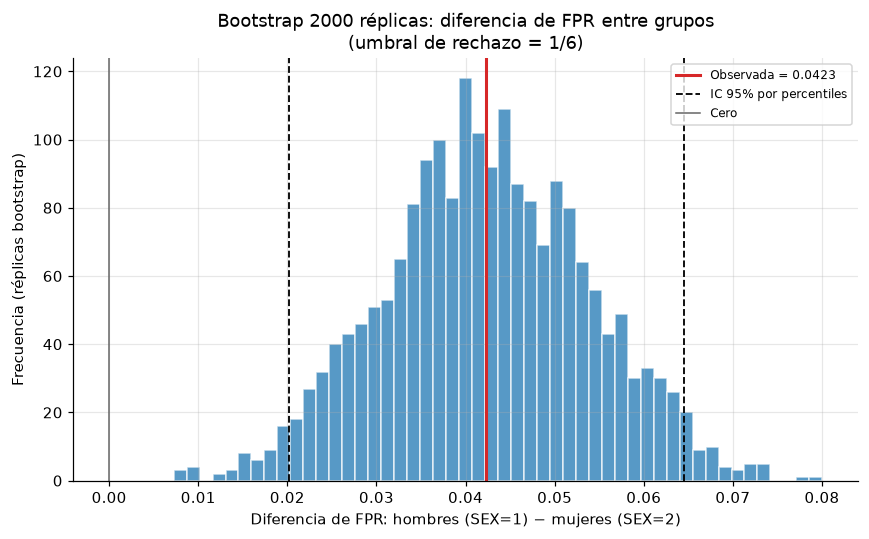

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(
    diferencias_fpr[np.isfinite(diferencias_fpr)],
    bins=50,
    color="tab:blue",
    alpha=0.75,
    edgecolor="white",
)
ax.axvline(
    dif_fpr_observada,
    color="tab:red",
    linewidth=2,
    label=f"Observada = {dif_fpr_observada:.4f}",
)
ax.axvline(
    tabla_bootstrap.loc[0, "ic95_inferior"],
    color="black",
    linestyle="--",
    linewidth=1.2,
    label="IC 95% por percentiles",
)
ax.axvline(
    tabla_bootstrap.loc[0, "ic95_superior"],
    color="black",
    linestyle="--",
    linewidth=1.2,
)
ax.axvline(0.0, color="0.4", linewidth=1.0, label="Cero")
ax.set_xlabel("Diferencia de FPR: hombres (SEX=1) − mujeres (SEX=2)")
ax.set_ylabel("Frecuencia (réplicas bootstrap)")
ax.set_title(
    "Bootstrap 2000 réplicas: diferencia de FPR entre grupos\n"
    "(umbral de rechazo = 1/6)"
)
ax.legend(loc="upper right", fontsize=8)
fig.tight_layout()
ruta_hist_fpr = RESULTADOS / "05_hist_fpr_diferencia.png"
fig.savefig(ruta_hist_fpr, bbox_inches="tight")
plt.show()

El histograma de `FPR_H − FPR_M` está casi completo a la derecha del cero:
la masa de réplicas se concentra alrededor de `0.042` y los límites del IC
quedan en `0.020` y `0.064`. Esto refuerza la lectura de la tabla anterior:
la mayor tasa de falsos positivos en hombres es una diferencia consistente,
no un artefacto de una sola muestra. La figura se guardó en
`resultados/05_hist_fpr_diferencia.png`.

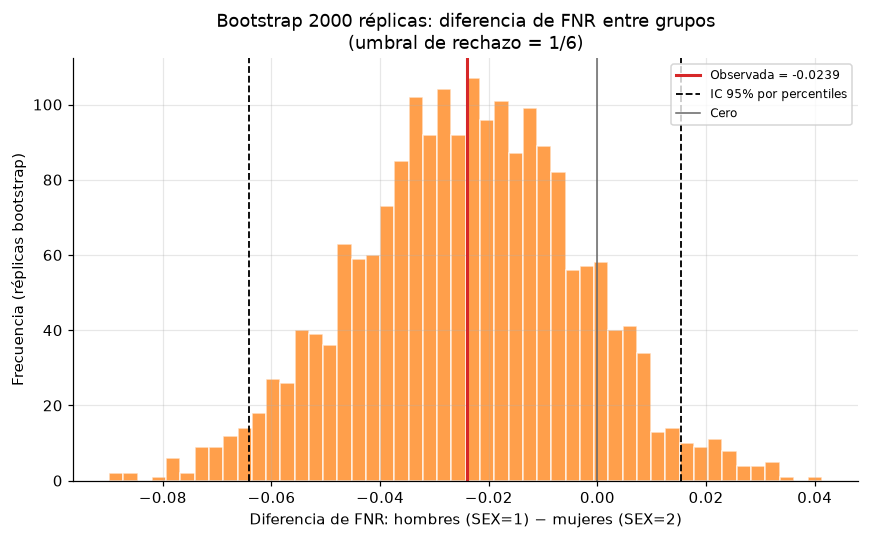

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(
    diferencias_fnr[np.isfinite(diferencias_fnr)],
    bins=50,
    color="tab:orange",
    alpha=0.75,
    edgecolor="white",
)
ax.axvline(
    dif_fnr_observada,
    color="tab:red",
    linewidth=2,
    label=f"Observada = {dif_fnr_observada:.4f}",
)
ax.axvline(
    tabla_bootstrap.loc[1, "ic95_inferior"],
    color="black",
    linestyle="--",
    linewidth=1.2,
    label="IC 95% por percentiles",
)
ax.axvline(
    tabla_bootstrap.loc[1, "ic95_superior"],
    color="black",
    linestyle="--",
    linewidth=1.2,
)
ax.axvline(0.0, color="0.4", linewidth=1.0, label="Cero")
ax.set_xlabel("Diferencia de FNR: hombres (SEX=1) − mujeres (SEX=2)")
ax.set_ylabel("Frecuencia (réplicas bootstrap)")
ax.set_title(
    "Bootstrap 2000 réplicas: diferencia de FNR entre grupos\n"
    "(umbral de rechazo = 1/6)"
)
ax.legend(loc="upper right", fontsize=8)
fig.tight_layout()
ruta_hist_fnr = RESULTADOS / "05_hist_fnr_diferencia.png"
fig.savefig(ruta_hist_fnr, bbox_inches="tight")
plt.show()

El histograma de `FNR_H − FNR_M` está centrado a la izquierda de cero, pero
una parte importante de las réplicas cae a la derecha: el IC va de `-0.064`
a `0.015` y cruza el cero. Por eso no se puede afirmar que los hombres tengan
un `FNR` sistemáticamente menor; la diferencia observada de `-0.024` es
compatible con ruido muestral. La figura se guardó en
`resultados/05_hist_fnr_diferencia.png`.

## 6. Cierre del inciso (c)

- Se usaron las probabilidades **calibradas** (`prob_calibrada`, método
  global isotónico) del archivo `04_probabilidades_calibradas_test.csv`.
- El umbral del banco fue `1/6`, con rechazo cuando el puntaje es `>= 1/6`.
- La tabla por grupo quedó en `resultados/05_tabla_grupos.csv` y no produjo
  divisiones entre cero.
- La identidad `FPR = p/(1-p) · (1-PPV)/PPV · (1-FNR)` se cumple con error
  de punto flotante (`5.55e-17` en hombres y `0.0` en mujeres), lo que
  confirma la consistencia interna de la tabla.
- El bootstrap de 2,000 réplicas no produjo réplicas inválidas. La
  diferencia de `FPR` es positiva y su IC del 95% no contiene el 0; la
  diferencia de `FNR` sí contiene el 0 y puede ser ruido.

Esta libreta no pasa al Problema 2.